<a href="https://colab.research.google.com/github/THE5NEON/Python-Labs/blob/main/%D0%9B%D0%A03_%D0%A2%D0%BE%D1%87%D0%B5%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

**Виконав:** Точенюк Ярослав, група 4-9.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import io, gzip, base64
sns.set_theme(style='whitegrid', palette='deep')


## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
UPLOAD = False
if UPLOAD:
    from google.colab import files
    uploaded = files.upload()
    name = next(k for k in uploaded if k.lower().endswith('.csv'))
    df = pd.read_csv(io.BytesIO(uploaded[name]))
else:
    raw = gzip.decompress(base64.b64decode('...'))
    df = pd.read_csv(io.BytesIO(raw))
print('Розмір даних:', df.shape)


Розмір даних: (1000, 8)


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [3]:
USE_KAGGLE = False
if USE_KAGGLE:
    import kagglehub
    folder = Path(kagglehub.dataset_download('prokshitha/home-value-insights'))
    candidates = list(folder.rglob('*.csv'))
    required = {'Square_Footage','Num_Bedrooms','Num_Bathrooms','Year_Built','Lot_Size','Garage_Size','Neighborhood_Quality','House_Price'}
    for path in candidates:
        candidate = pd.read_csv(path)
        if required.issubset(candidate.columns):
            df = candidate
            break
    else:
        raise ValueError('Не знайдено CSV з потрібними ознаками')
print('Активний набір:', df.shape)


Активний набір: (1000, 8)


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [4]:
display(df.head()); df.info()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [5]:
print('Дублікатів:', df.duplicated().sum())

Дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [6]:
display(df.isna().sum().to_frame('Пропуски'))

,Пропуски
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Square_Footage,1000.0,2815.422000,1255.514921,503.000000,1749.500000,2862.500000,3849.500000,4.999000e+03
Num_Bedrooms,1000.0,2.990000,1.427564,1.000000,2.000000,3.000000,4.000000,5.000000e+00
Num_Bathrooms,1000.0,1.973000,0.820332,1.000000,1.000000,2.000000,3.000000,3.000000e+00
Year_Built,1000.0,1986.550000,20.632916,1950.000000,1969.000000,1986.000000,2004.250000,2.022000e+03
Lot_Size,1000.0,2.778087,1.297903,0.506058,1.665946,2.809740,3.923317,4.989303e+00
Garage_Size,1000.0,1.022000,0.814973,0.000000,0.000000,1.000000,2.000000,2.000000e+00
Neighborhood_Quality,1000.0,5.615000,2.887059,1.000000,3.000000,6.000000,8.000000,1.000000e+01
House_Price,1000.0,618861.018647,253568.058375,111626.853424,401648.228909,628267.291129,827141.277637,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [8]:
display(df['Neighborhood_Quality'].value_counts().sort_index())

,count
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

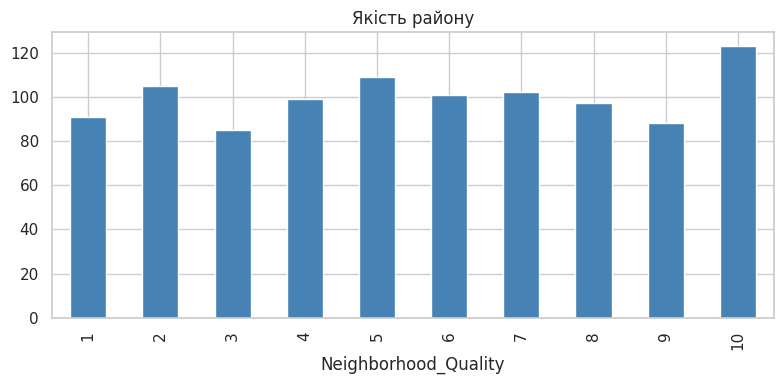

In [9]:
plt.figure(figsize=(8,4)); df['Neighborhood_Quality'].value_counts().sort_index().plot.bar(color='steelblue'); plt.title('Якість району'); plt.tight_layout(); plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [10]:
display(df['Num_Bathrooms'].value_counts().sort_index())

,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

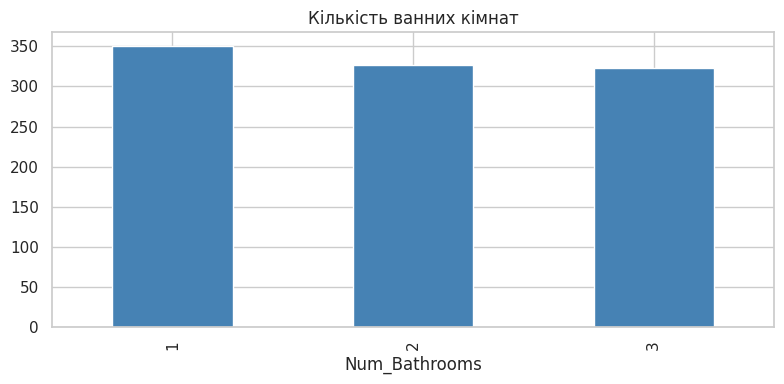

In [11]:
plt.figure(figsize=(8,4)); df['Num_Bathrooms'].value_counts().sort_index().plot.bar(color='steelblue'); plt.title('Кількість ванних кімнат'); plt.tight_layout(); plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

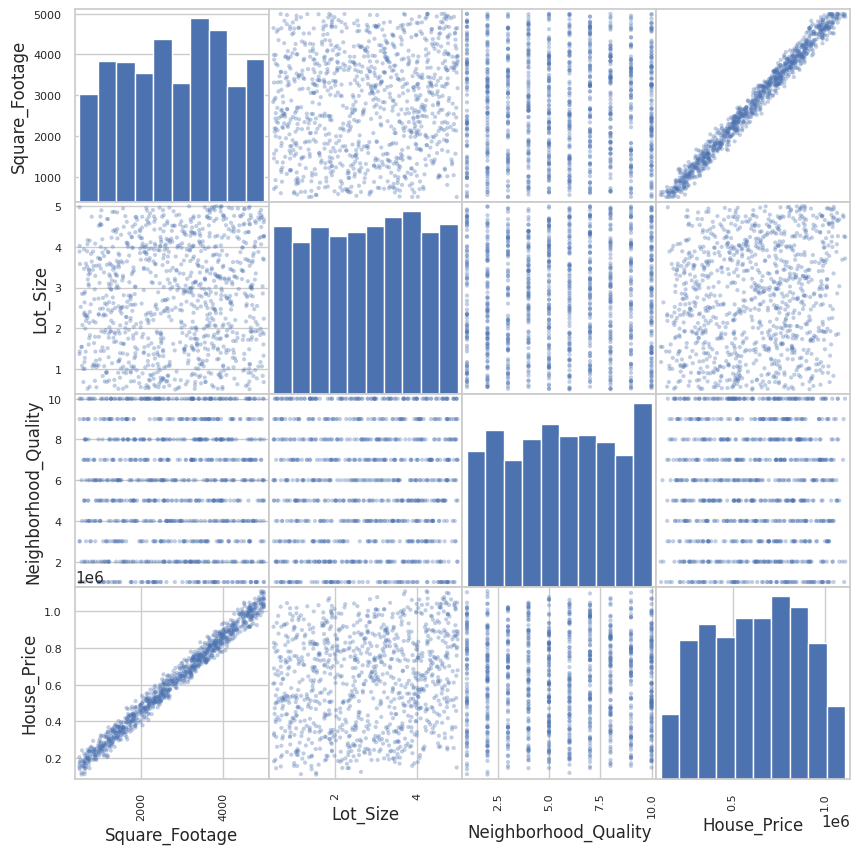

Найсильніша лінійна залежність серед цих ознак: Square_Footage


In [12]:
pd.plotting.scatter_matrix(df[['Square_Footage','Lot_Size','Neighborhood_Quality','House_Price']],diagonal='hist',figsize=(10,10),alpha=.35); plt.show()
print('Найсильніша лінійна залежність серед цих ознак:', df[['Square_Footage','Lot_Size','Neighborhood_Quality','House_Price']].corr()['House_Price'].drop('House_Price').abs().idxmax())

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

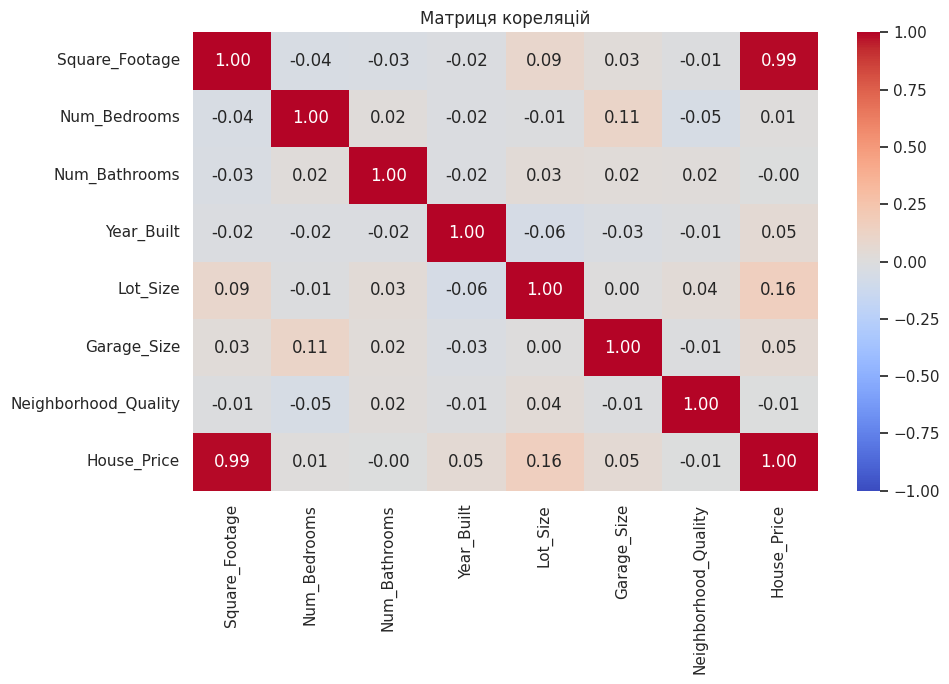

In [13]:
corr = df.select_dtypes(include='number').corr()
plt.figure(figsize=(10,7)); sns.heatmap(corr,annot=True,fmt='.2f',cmap='coolwarm',center=0,vmin=-1,vmax=1); plt.title('Матриця кореляцій'); plt.tight_layout(); plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [14]:
display(corr['House_Price'].drop('House_Price').sort_values(ascending=False))

,House_Price
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [15]:
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [16]:
features = ['Square_Footage','Num_Bedrooms','Num_Bathrooms','Year_Built','Lot_Size','Garage_Size','Neighborhood_Quality']
clean = df[features+['House_Price']].apply(pd.to_numeric,errors='coerce').drop_duplicates().dropna(subset=['House_Price'])
X = clean[features]; y = clean['House_Price']
print(X.shape, y.shape)

(1000, 7) (1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [17]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print('Навчальна:', X_train.shape, 'Тестова:', X_test.shape)

Навчальна: (800, 7) Тестова: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [18]:
models = {
 'Linear Regression': make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LinearRegression()),
 'Ridge': make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),Ridge(alpha=1)),
 'Lasso': make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),Lasso(alpha=1,max_iter=10000)),
 'Random Forest': make_pipeline(SimpleImputer(strategy='median'),RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=1)),
 'Gradient Boosting': make_pipeline(SimpleImputer(strategy='median'),GradientBoostingRegressor(random_state=42))
}

### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [19]:
def metrics(y_true, y_pred):
    return {'R²':r2_score(y_true,y_pred),'MAE':mean_absolute_error(y_true,y_pred),'MSE':mean_squared_error(y_true,y_pred)}
predictions = {}; rows = []
for name, model in models.items():
    model.fit(X_train,y_train)
    predictions[name] = model.predict(X_test)
    rows.append({'Модель':name,**metrics(y_test,predictions[name])})
results = pd.DataFrame(rows).set_index('Модель')
display(results.sort_values('R²',ascending=False))

,R²,MAE,MSE
Модель,,,
Linear Regression,0.998426,8174.583600,1.014348e+08
Lasso,0.998426,8174.748374,1.014366e+08
Ridge,0.998410,8241.586911,1.024810e+08
Gradient Boosting,0.996510,12305.217615,2.249656e+08
Random Forest,0.993886,16114.289644,3.941317e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

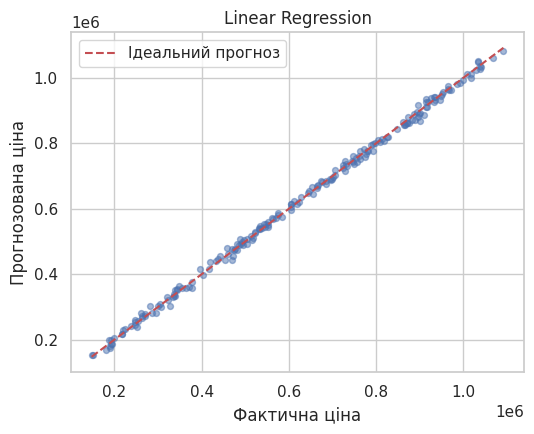

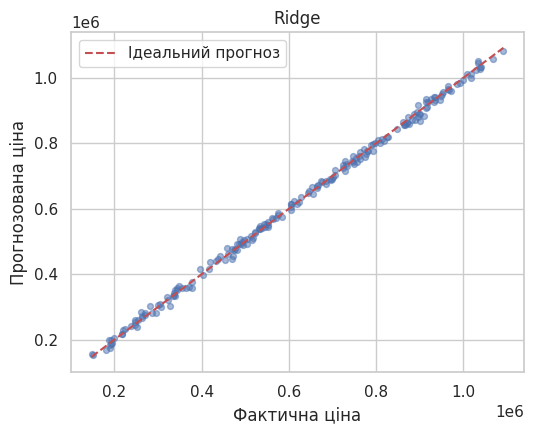

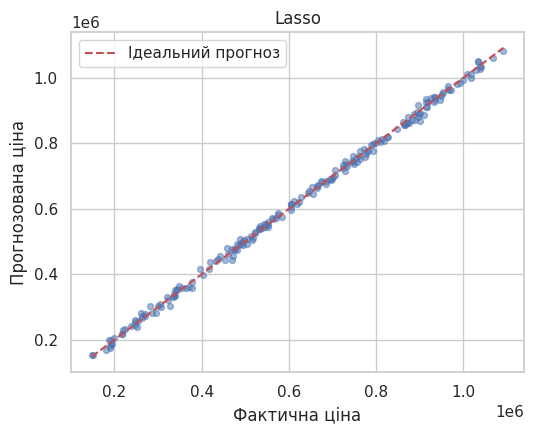

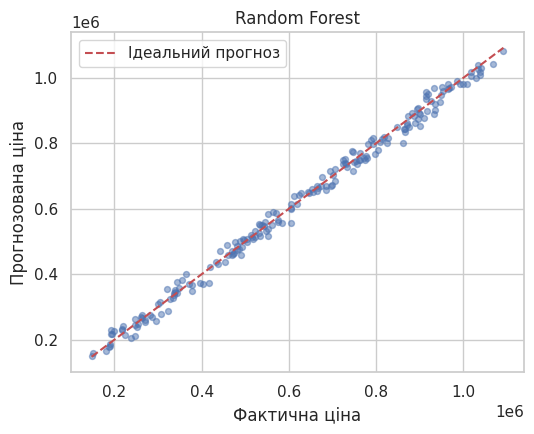

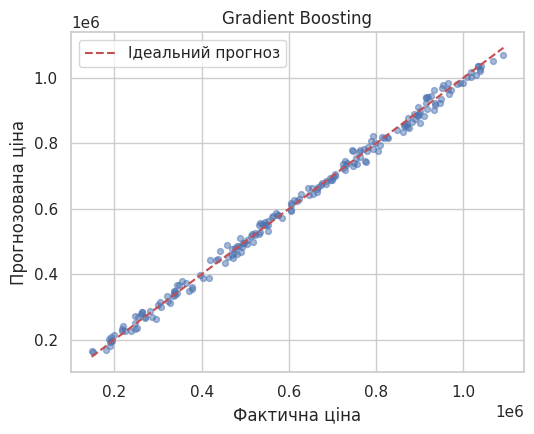

In [20]:
for name, pred in predictions.items():
    lo = min(y_test.min(),pred.min()); hi = max(y_test.max(),pred.max())
    plt.figure(figsize=(5.5,4.5)); plt.scatter(y_test,pred,alpha=.5,s=18)
    plt.plot([lo,hi],[lo,hi],'r--',label='Ідеальний прогноз')
    plt.xlabel('Фактична ціна'); plt.ylabel('Прогнозована ціна'); plt.title(name); plt.legend(); plt.tight_layout(); plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [21]:
forest = make_pipeline(SimpleImputer(strategy='median'),RandomForestRegressor(random_state=42,n_jobs=1))
param_grid = {'randomforestregressor__n_estimators':[50,100], 'randomforestregressor__max_features':[0.7,1.0], 'randomforestregressor__max_depth':[None,10], 'randomforestregressor__min_samples_split':[2,5]}
grid = GridSearchCV(forest,param_grid,cv=KFold(3,shuffle=True,random_state=42),scoring='r2',n_jobs=2)
grid.fit(X_train,y_train)
best_params = {k.split('__',1)[1]:v for k,v in grid.best_params_.items()}
print('Найкращі параметри:',best_params); print('R² CV:',grid.best_score_)

Найкращі параметри: {'max_depth': None, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 100}
R² CV: 0.9919642204730813


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [22]:
optimized = make_pipeline(SimpleImputer(strategy='median'),RandomForestRegressor(**best_params,random_state=42,n_jobs=1))
optimized.fit(X_train,y_train)
opt_pred = optimized.predict(X_test)
opt_metrics = metrics(y_test,opt_pred)
display(pd.DataFrame([opt_metrics],index=['Оптимізований Random Forest']))

,R²,MAE,MSE
Оптимізований Random Forest,0.993886,16114.289644,3.941317e+08


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [23]:
comparison = pd.DataFrame([results.loc['Random Forest'].to_dict(),opt_metrics],index=['Базова','Оптимізована'])
display(comparison)
print('Зміни (після мінус до):'); display(comparison.iloc[1]-comparison.iloc[0])

,R²,MAE,MSE
Базова,0.993886,16114.289644,3.941317e+08
Оптимізована,0.993886,16114.289644,3.941317e+08


Зміни (після мінус до):


,0
R²,0.0
MAE,0.0
MSE,0.0


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Висновок розраховується за фактичними метриками нижче.

In [24]:
delta = comparison.iloc[1]-comparison.iloc[0]
print(f'Зміна R²: {delta["R²"]:+.5f}; MAE: {delta["MAE"]:+.2f}; MSE: {delta["MSE"]:+.2f}.')
print('За R² оптимізація покращила тестовий результат.' if delta['R²']>0 else 'За R² оптимізація не покращила тестовий результат.')
print('Доцільність вибору слід оцінювати за крос-валідацією, величиною похибок і вартістю навчання.')

Зміна R²: +0.00000; MAE: +0.00; MSE: +0.00.
За R² оптимізація не покращила тестовий результат.
Доцільність вибору слід оцінювати за крос-валідацією, величиною похибок і вартістю навчання.


## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [25]:
actual = y_test.to_numpy(); pred = predictions['Linear Regression']
error = np.divide(np.abs(actual-pred)*100,np.abs(actual),out=np.full(actual.shape,np.nan,dtype=float),where=actual!=0)
forecast = pd.DataFrame({'Фактична ціна':actual,'Прогнозована ціна':pred,'Похибка, %':error})
display(forecast.sample(n=min(10,len(forecast)),random_state=42).round(2))
print('Середня абсолютна відсоткова похибка:',round(forecast['Похибка, %'].mean(),2))

,Фактична ціна,Прогнозована ціна,"Похибка, %"
95,1068538.11,1059729.02,0.82
15,194353.74,187868.55,3.34
30,270230.64,279715.82,3.51
158,986006.86,981949.27,0.41
128,953339.73,957382.95,0.42
115,914555.75,909764.27,0.52
69,746167.73,742469.14,0.50
170,646766.29,654445.55,1.19
174,523323.07,524605.44,0.25
45,1008539.16,1011343.64,0.28


Середня абсолютна відсоткова похибка: 1.66


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

Підсумок на основі результатів виконання наведено нижче.

In [26]:
all_results = pd.concat([results,pd.DataFrame([opt_metrics],index=['Random Forest optimized'])])
best = all_results['R²'].idxmax()
print('Побудовано п’ять базових моделей та оптимізований Random Forest.')
print('Найкраща за R²:',best); display(all_results.loc[[best]])
print(f'Для Linear Regression середня абсолютна відсоткова похибка: {forecast["Похибка, %"].mean():.2f}%.')
print('На якість впливають площа, розмір ділянки, район, якість даних, пропуски та невраховані чинники.')
assert len(models)==5 and len(predictions)==5
assert len(X_train)+len(X_test)==len(X) and not set(X_train.index)&set(X_test.index)
assert all(np.isfinite(v).all() for v in predictions.values())
assert np.isfinite(all_results.to_numpy()).all()
assert len(grid.cv_results_["params"])==16
print('П’ять контрольних перевірок пройдено.')

Побудовано п’ять базових моделей та оптимізований Random Forest.
Найкраща за R²: Linear Regression


,R²,MAE,MSE
Linear Regression,0.998426,8174.5836,1.014348e+08


Для Linear Regression середня абсолютна відсоткова похибка: 1.66%.
На якість впливають площа, розмір ділянки, район, якість даних, пропуски та невраховані чинники.
П’ять контрольних перевірок пройдено.
